<a href="https://colab.research.google.com/github/Sunil-Paliwal/ai-enabled-drug-discovery-and-synthesis/blob/main/03_bioisostere_explorer/bioisostere_explorer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


<table><tr><td style="background:#fff8e6; border-left:5px solid #d68910; padding:10px 16px; font-family:system-ui,sans-serif; font-size:14px;">
<b>&#9654;&nbsp; To run this notebook, click the <i>Open in Colab</i> badge above.</b><br>
GitHub shows a read-only preview &mdash; the code will not run on this page. Colab runs it in your browser for free; all you need is a Google account, and nothing is installed on your computer.<br>
<span style="color:#555;">Once it opens in Colab, run the first two cells (install, then setup) before anything else.</span>
</td></tr></table>


### Bioisostere Explorer

**Replace a functional group without losing the interaction it makes.**

<div style="font-size:13px; color:#333; border-left:3px solid #2c5c40;
            padding:8px 16px; margin:12px 0; background:#f7f9f7;">
<b>Author:</b> Dr. Sunil Paliwal, Department of Chemistry and Chemical Biology,
Stevens Institute of Technology<br>
<b>Module:</b> 03 of <a href="https://github.com/Sunil-Paliwal/ai-enabled-drug-discovery-and-synthesis">AI-Enabled
Drug Discovery and Synthesis</a> &nbsp;&middot;&nbsp;
<b>Version:</b> 1.0 &nbsp;&middot;&nbsp; <b>Licence:</b> MIT<br>
<b>Status:</b> Developed for teaching and research in drug discovery and medicinal
chemistry.<br>
<b>Cite as:</b> Paliwal, S. <i>Bioisostere Explorer.</i> GitHub, 2026.
github.com/Sunil-Paliwal/ai-enabled-drug-discovery-and-synthesis<br>
<span style="font-size:12px; color:#666;">Working from a saved copy? The link above
always has the current version.</span>
</div>


---

## Background

A **bioisostere** is a group you can swap into a molecule in place of another and still
keep the biology working. The classic example is a carboxylic acid replaced by a tetrazole:
different atoms, different ring, but both are acidic, both are negatively charged at
physiological pH, and both make the same salt bridge — while the tetrazole resists the
metabolism and poor permeability that plague acids.

That is the whole point. Almost every group that binds well also brings a problem with it:
acids do not cross membranes, basic amines hit hERG, esters are hydrolysed, flat aromatics
are oxidised, amides are cleaved. A bioisostere lets you **keep the interaction and drop the
liability** — or at least trade it for one you can live with.

<p align="center">
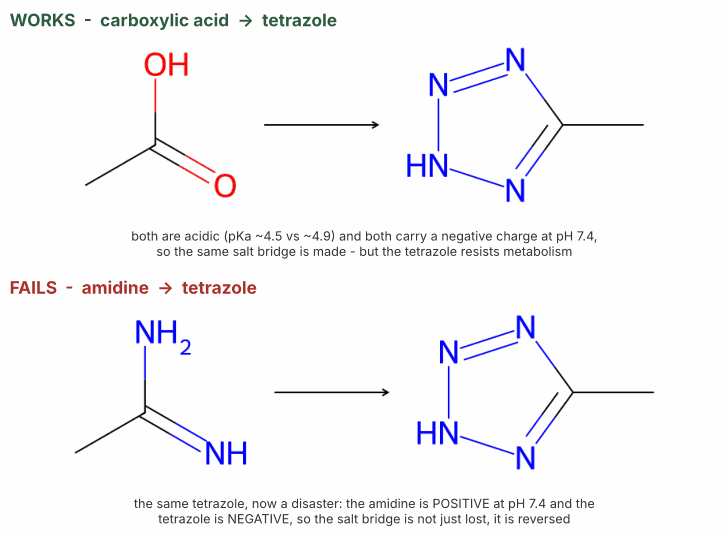<br>
<i>The same tetrazole: a textbook replacement for one group, and a disaster for another.</i>
</p>

The difficulty is that "similar" depends entirely on context. A tetrazole is an excellent
carboxylic acid replacement and a catastrophic amidine replacement: same ring, opposite
charge. Two groups are bioisosteric *for a particular interaction*, never in general.

So this notebook asks what your group is **doing** before it suggests anything — making a
salt bridge, donating a hydrogen bond, stacking against an aromatic — and only offers
replacements that preserve that role. For each one it shows what you gain and what you pay,
then builds the new molecules in 3D so you can dock them.

---

## Introduction — the workflow

You are looking at a ligand in a binding site — in PyMOL, Chimera, Maestro, MOE, or just a
figure in a paper. One group is making an interaction you care about: a salt bridge, a
hydrogen bond, a pi stack. You want to know what else could sit there.

This notebook takes the SMILES of that group and returns replacements that **preserve the
interaction** while changing the properties, then builds the new molecules and writes a 3D
SDF you can dock in any program.

---

### The one rule that matters

A bioisostere is only a bioisostere *for a particular interaction*.

A tetrazole is an excellent replacement for a carboxylic acid and a catastrophic
replacement for an amidine — same ring, opposite charge. So the notebook asks what the
group is **doing** before it suggests anything, and will not hand you something with the
wrong charge unless you ask for it.

<div style="border:2px solid #3f7d58; border-radius:10px; padding:4px 22px 18px 22px;
            background:#f4faf6; color:#1b1b1b; font-size:15px;">

<h2 style="color:#2c5c40; margin-bottom:2px;"><b>How to use this notebook</b></h2>

<p>There is a lot of text in this notebook, so look for the <b>green bars</b>: they mark
<b>&#9733; Step 1</b>, <b>&#9733; Step 2</b> and <b>&#9733; Step 3</b>, which is all you
have to follow. Only <b>two</b> cells need editing, and those steps carry an orange
<b>you edit this one</b> tag. Everything else you simply run.</p>

<table style="width:100%; border-collapse:collapse; background:#ffffff; color:#1b1b1b;">
<tr style="background:#e4efe8;">
  <th style="text-align:left; padding:7px 10px; width:4.5em;">Cell</th>
  <th style="text-align:left; padding:7px 10px;">What it does</th>
  <th style="text-align:left; padding:7px 10px; width:7em;">You edit it?</th>
</tr>

<tr><td colspan="3" style="padding:7px 10px; background:#f0f5f2;"><b>Step 1 &mdash; Setup</b></td></tr>
<tr><td style="padding:7px 10px;"><b>1</b></td>
    <td style="padding:7px 10px;">Installs RDKit. Takes about a minute.</td>
    <td style="padding:7px 10px;">no</td></tr>
<tr><td style="padding:7px 10px;"><b>2</b></td>
    <td style="padding:7px 10px;">Loads the search engine and the database of 77 groups.</td>
    <td style="padding:7px 10px;">no</td></tr>

<tr><td colspan="3" style="padding:7px 10px; background:#f0f5f2;"><b>Step 2 &mdash; Find replacements</b></td></tr>
<tr><td style="padding:7px 10px;"><b>3 &#9733;</b></td>
    <td style="padding:7px 10px;">You type the group you want to replace. Returns the ranked table and structures.</td>
    <td style="padding:7px 10px;"><b>YES</b></td></tr>
<tr><td style="padding:7px 10px;"><b>4</b></td>
    <td style="padding:7px 10px;">Optional. Shows the replacements that give up the charge instead of keeping it.</td>
    <td style="padding:7px 10px;">no</td></tr>

<tr><td colspan="3" style="padding:7px 10px; background:#f0f5f2;"><b>Step 3 &mdash; Build the molecules</b></td></tr>
<tr><td style="padding:7px 10px;"><b>5 &#9733;</b></td>
    <td style="padding:7px 10px;">You type your whole ligand. Builds the new molecules and writes the SDF files.</td>
    <td style="padding:7px 10px;"><b>YES</b></td></tr>
<tr><td style="padding:7px 10px;"><b>6</b></td>
    <td style="padding:7px 10px;">Downloads an SDF to your computer.</td>
    <td style="padding:7px 10px;">no</td></tr>
<tr><td style="padding:7px 10px;"><b>7</b></td>
    <td style="padding:7px 10px;">Optional. Writes the whole session to a PDF report.</td>
    <td style="padding:7px 10px;">your name</td></tr>

<tr><td colspan="3" style="padding:7px 10px; background:#f0f5f2;"><b>Exercises</b></td></tr>
<tr><td style="padding:7px 10px;"><b>8</b></td>
    <td style="padding:7px 10px;">Only for exercise 6 &mdash; adds a group of your own to the database.</td>
    <td style="padding:7px 10px;">for ex. 6</td></tr>
</table>

<p style="margin-top:14px;"><b>Two things that catch people out</b></p>
<ul>
<li><b>Every cell depends on the ones above it.</b> A <code>NameError</code> almost always
    means an earlier cell has not been run in this session.</li>
<li><b>Colab forgets everything when the runtime shuts down</b> &mdash; when you close the
    tab, or after it sits idle. You then have to run Step 1 again.</li>
</ul>

</div>

<div style="background:#2c5c40; color:#ffffff; padding:12px 22px; border-radius:8px;
            margin-top:28px;">
<h2 style="color:#ffffff; margin:0; font-size:30px;">&#9733; STEP 1 &mdash; Setup</h2>
</div>

**Cell 1** installs RDKit, **Cell 2** loads the engine and the database.
**Run both every time you open the notebook.** Colab starts with a fresh machine
each session, so nothing from last time is still loaded. It takes about a minute.

In [ ]:
# ===== CELL 1 =====
!pip install rdkit pandas --quiet
print('installing...')

In [ ]:
# ===== CELL 2 =====

# ---------------------------------------------------------------------------
# Bioisostere Explorer - engine.  You do not need to read or edit this cell.
# ---------------------------------------------------------------------------
from rdkit import Chem
from rdkit.Chem import (Descriptors, Crippen, rdMolDescriptors, Draw,
                        AllChem, rdMolAlign, QED)
from rdkit import RDLogger
import pandas as pd, math
RDLogger.DisableLog("rdApp.*")
try:
    from rdkit.Chem.Draw import IPythonConsole
    IPythonConsole.molSize = (300, 200)
except ImportError:
    pass
try:
    from IPython.display import display
except ImportError:
    display = print

# ---- what a group can be doing in a binding site -------------------------
ROLE_MEANING = {
 "ANION":   "negative at pH 7.4 - salt bridge to Arg/Lys/His, or metal binding",
 "CATION":  "positive at pH 7.4 - salt bridge to Asp/Glu, or cation-pi",
 "HBD_HBA": "neutral, both donates AND accepts a hydrogen bond",
 "HBA":     "neutral hydrogen-bond acceptor only",
 "ARYL":    "flat ring - pi stacking, shape filling",
 "LIPO":    "hydrophobic contact, halogen bond, or metabolic blocking",
}

# ---- role perception: what is this group doing? --------------------------
ROLE_RULES = [
 ("ANION",   "carboxylic acid",   "[CX3](=O)[OX2H1,OX1-]"),
 ("ANION",   "tetrazole",         "c1nnn[nH,n-]1"),
 ("ANION",   "acylsulfonamide",   "[CX3](=O)[NX3H1,NX3-][SX4](=O)(=O)"),
 ("ANION",   "sulfonic acid",     "[SX4](=O)(=O)[OX2H1,OX1-]"),
 ("ANION",   "phosphonic acid",   "[PX4](=O)[OX2H1,OX1-]"),
 ("ANION",   "hydroxamic acid",   "[CX3](=O)[NX3][OX2H1,OX1-]"),
 ("CATION",  "guanidine",         "[NX3][CX3](=[NX2,NX3+])[NX3]"),
 ("CATION",  "amidine",           "[CX3](=[NX2,NX3+])[NX3]"),
 ("CATION",  "aliphatic amine",   "[NX3;H2,H1,H0;!$(N[a]);!$(NC=[O,N,S]);!$(N[SX4]);!$(N#*);!$(N=*)]"),
 ("CATION",  "amino-heteroarene", "[NX3H2][a]"),
 ("HBD_HBA", "sulfonamide",       "[SX4](=O)(=O)[NX3H1,NX3H2]"),
 ("HBD_HBA", "urea",              "[NX3][CX3](=O)[NX3]"),
 ("HBD_HBA", "amide",             "[CX3](=O)[NX3H1,NX3H2]"),
 ("HBD_HBA", "hydroxyl",          "[OX2H1]"),
 ("HBA",     "nitrile",           "[NX1]#[CX2]"),
 ("HBA",     "ester",             "[CX3](=O)[OX2][#6]"),
 ("HBA",     "ketone",            "[#6][CX3](=O)[#6]"),
 ("HBA",     "tertiary amide",    "[CX3](=O)[NX3H0]"),
 ("HBA",     "sulfone",           "[SX4](=O)(=O)[#6]"),
 ("HBA",     "pyridine-type N",   "[nX2;r6]"),
 ("HBA",     "ether",             "[OX2]([#6])[#6]"),
 ("ARYL",    "phenyl",            "c1ccccc1"),
 ("ARYL",    "heteroaryl (5)",    "[a;!c]1[a][a][a][a]1"),
 ("ARYL",    "heteroaryl (6)",    "[a;!c]1[a][a][a][a][a]1"),
 ("LIPO",    "CF3",               "[CX4](F)(F)F"),
 ("LIPO",    "halogen",           "[Cl,Br,I]"),
 ("LIPO",    "tert-butyl",        "[CX4]([CH3])([CH3])[CH3]"),
]
_PATTS = [(r, n, Chem.MolFromSmarts(s)) for r, n, s in ROLE_RULES]
# the same SMARTS double as "what to cut out" patterns, looked up by name
REMOVE_SMARTS = {n: s for _, n, s in ROLE_RULES}
REMOVE_SMARTS.update({                      # friendlier aliases
 "carboxylate": "[CX3](=O)[OX2H1,OX1-]",
 "primary amide": "[CX3](=O)[NX3H2]",
 "amine": "[NX3;H2,H1;!$(N[a]);!$(NC=[O,N,S])]",
 "benzene": "c1ccccc1",
 "chloro": "[Cl]",
 "methyl": "[CX4H3]",
})

def cap(frag):
    """[*] attachment point -> methyl, so properties are computable."""
    return Chem.MolFromSmiles(frag.replace("[*]", "C"))

def _props(m):
    return dict(MW=Descriptors.MolWt(m), TPSA=rdMolDescriptors.CalcTPSA(m),
                cLogP=Crippen.MolLogP(m), HBD=rdMolDescriptors.CalcNumHBD(m),
                HBA=rdMolDescriptors.CalcNumHBA(m))

def frac_ionised(pka, role, pH=7.4):
    """What fraction of the group actually carries its charge at pH 7.4.

    Henderson-Hasselbalch. An acid is ionised when pH > pKa, a base when pH < pKa.
    This is why a single +1/-1 label is not enough: a base with pKa 7.0 is only
    about a quarter protonated at 7.4, not 'a cation'.
    """
    if pka is None:
        return None
    if role == "ANION":
        return 1.0 / (1.0 + 10 ** (pka - pH))
    if role == "CATION":
        return 1.0 / (1.0 + 10 ** (pH - pka))
    return None


def roles_of(smiles):
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return None, []
    return m, [(r, n) for r, n, p in _PATTS if p is not None and m.HasSubstructMatch(p)]

_LAST = {}          # remembers the most recent search, so swap() can default to it
_LAST_BUILD = {}    # the most recent build
_BUILDS = []        # EVERY build this session, so a report covers them all
                    # (Step 3 with WHICH="both" calls swap twice - both must survive)


def show_table(df):
    """Display a results table with missing values shown as '-' rather than NaN.

    NaN just means 'not applicable here' - a group with no ionisable centre has no
    pKa, and the parent molecule has no RMSD against itself - but it reads like an
    error, so it is blanked out.
    """
    if df is None or len(df) == 0:
        print("Nothing to show.")
        return None
    return df.astype(object).where(pd.notna(df), "-")


def draw(df, n=8, cols=("score",), per_row=4):
    """Draw the structures from any isosteres() result table.

    df    a table returned by isosteres()
    cols  which column(s) to print under each structure
    """
    if df is None or len(df) == 0:
        print("Nothing to draw."); return None
    mols, legends = [], []
    for _, r in df.head(n).iterrows():
        m = cap(r["SMILES"])
        if m is None:
            continue
        mols.append(m)
        if str(r["replacement"]).startswith(">>>"):
            legends.append(f"YOUR GROUP\n{r['SMILES']}")
        else:
            bits = []
            for c in cols:                      # skip blanks: None and pandas NaN alike
                if c not in r:
                    continue
                v = r[c]
                if v is None or (isinstance(v, float) and pd.isna(v)):
                    continue
                bits.append(f"{c} {v}")
            legends.append(r["replacement"] + ("\n" + "  ".join(bits) if bits else ""))
    if not mols:
        print("Nothing to draw."); return None
    return Draw.MolsToGridImage(mols, legends=legends, molsPerRow=per_row,
                                subImgSize=(230, 180))

# Bioisostere group database.
# role      : pharmacophore role preserved (the thing that must NOT change)
# q         : formal charge at pH 7.4 (-1 anion, +1 cation, 0 neutral)
# pka       : approximate pKa of the ionisable centre (None if not ionisable)
# frag      : fragment SMILES, [*] = attachment point to the rest of the molecule
# note      : what you trade by using it / where it is precedented
# flag      : liability worth warning students about

GROUPS = [
# ---------------- ANIONIC (acidic, ionised at 7.4) ----------------
dict(name="carboxylic acid", prec=5,        frag="[*]C(=O)O",            role="ANION", q=-1, pka=4.5,  note="Reference acid. Strong salt bridges but poor permeability, glucuronidation, acyl-glucuronide risk."),
dict(name="tetrazole (1H-5-yl)", prec=5,    frag="[*]c1nn[nH]n1",        role="ANION", q=-1, pka=4.9,  note="Classic COOH isostere; ~2x the area, more lipophilic when ionised, metabolically robust. Sartans (losartan, valsartan)."),
dict(name="1,2,4-oxadiazol-5(4H)-one", prec=3, frag="[*]c1noc(=O)[nH]1", role="ANION", q=-1, pka=6.5,  note="Weaker acid than COOH; useful when full ionisation hurts permeability."),
dict(name="1,2,4-triazol-5(4H)-one", prec=3,frag="[*]C1=NNC(=O)N1",      role="ANION", q=-1, pka=7.0,  note="Partially ionised at 7.4; softer charge."),
dict(name="acylsulfonamide", prec=4,        frag="[*]C(=O)NS(=O)(=O)C",  role="ANION", q=-1, pka=4.0,  note="Acidity close to COOH, much larger and more lipophilic. Common in antagonists needing extra reach."),
dict(name="sulfonamide (N-aryl)", prec=3,   frag="[*]S(=O)(=O)Nc1ccccc1",role="ANION", q=-1, pka=6.5,  note="Acidic only when N-aryl/N-acyl activated. Tetrahedral, not planar - changes vector geometry."),
dict(name="hydroxamic acid", prec=4,        frag="[*]C(=O)NO",           role="ANION", q=0,  pka=9.0,  note="Only ~2% ionised at 7.4, so it does NOT replace a carboxylate's charge - its value is metal chelation, the go-to for Zn enzymes (HDAC, MMP).", flag="metal chelator; often promiscuous"),
dict(name="3-hydroxyisoxazole", prec=2,     frag="[*]c1cc(O)no1",        role="ANION", q=-1, pka=6.0,  note="Planar, compact acid; glutamate-receptor ligands (AMPA/ibotenic acid family)."),
dict(name="thiazolidine-2,4-dione", prec=3, frag="[*]C1SC(=O)NC1=O",     role="ANION", q=-1, pka=6.8,  note="Acidic CH; PPAR agonists (glitazones).", flag="reactive metabolite / idiosyncratic tox history"),
dict(name="squaric acid (mono-amide)", prec=2, frag="[*]NC1=C(O)C(=O)C1=O", role="ANION", q=-1, pka=3.5, note="Very strong, rigid, planar bidentate acid; large footprint."),
dict(name="phosphonic acid", prec=2,        frag="[*]P(=O)(O)O",         role="ANION", q=-1, pka=2.0,  note="Dianionic at 7.4. Excellent affinity, essentially no oral absorption.", flag="dianion - permeability near zero"),
dict(name="tetronic acid", prec=1,          frag="[*]C1=C(O)C(=O)OC1",   role="ANION", q=-1, pka=3.5,  note="Rigid cyclic enol acid."),
dict(name="2,6-difluorophenol", prec=2,     frag="[*]c1c(F)cccc1O",      role="ANION", q=-1, pka=7.1,  note="Neutral-ish acid; mimics COOH geometry with far better logD."),

# ---------------- CATIONIC (basic, protonated at 7.4) ----------------
dict(name="amidine", prec=5,                frag="[*]C(=N)N",            role="CATION", q=1, pka=11.5, note="Reference strong base. Planar, bidentate donor pair - ideal for Asp/Glu salt bridge.", flag="permanently charged; poor oral bioavailability"),
dict(name="guanidine", prec=5,              frag="[*]NC(=N)N",           role="CATION", q=1, pka=13.0, note="Even stronger and wider donor array; three donors.", flag="permanently charged"),
dict(name="2-aminoimidazole", prec=3,       frag="[*]c1cnc(N)[nH]1",     role="CATION", q=1, pka=8.5,  note="Cyclic amidine surrogate, attenuated basicity, planar."),
dict(name="2-aminopyridine", prec=4,        frag="[*]c1ccc(N)nc1",       role="CATION", q=0, pka=7.0,  note="Partially protonated at 7.4; donor-acceptor pair mimics amidine with a neutral fraction available for permeation."),
dict(name="4-aminopyridine", prec=3,        frag="[*]c1ccncc1N",         role="CATION", q=1, pka=9.1,  note="Strong aryl base; linear vector."),
dict(name="2-aminothiazole", prec=3,        frag="[*]c1nc(N)cs1",        role="CATION", q=0, pka=5.4,  note="Largely NEUTRAL at 7.4 - keeps the donor pair but loses the formal charge.", flag="charge lost vs amidine"),
dict(name="imidazole", prec=3,              frag="[*]c1cnc[nH]1",        role="CATION", q=0, pka=7.0,  note="Half protonated at 7.4; donor and acceptor in one ring.", flag="CYP heme binding risk"),
dict(name="primary alkylamine", prec=4,     frag="[*]CN",                role="CATION", q=1, pka=10.5, note="Flexible single donor; loses the bidentate geometry of an amidine."),
dict(name="piperidin-4-yl", prec=5,         frag="[*]C1CCNCC1",          role="CATION", q=1, pka=11.0, note="Saturated base, 3D, good for filling aliphatic pockets.", flag="hERG liability for basic amines"),
dict(name="pyrrolidin-3-yl", prec=4,        frag="[*]C1CCNC1",           role="CATION", q=1, pka=11.3, note="Compact saturated base."),
dict(name="piperazin-1-yl", prec=4,         frag="[*]N1CCNCC1",          role="CATION", q=1, pka=9.8,  note="Distal N tunable; common solubilising group."),
dict(name="morpholin-4-yl", prec=4,         frag="[*]N1CCOCC1",          role="CATION", q=0, pka=7.4,  note="N-substituted morpholine, pKa ~7.4 - about half protonated at physiological pH. Good solubility without the hERG risk of a strong base.", flag="only partly charged"),
dict(name="N-methylpiperazine", prec=4,     frag="[*]N1CCN(C)CC1",       role="CATION", q=1, pka=8.0,  note="Attenuated base, widely used to dial logD down."),
dict(name="azetidin-3-yl", prec=3,          frag="[*]C1CNC1",            role="CATION", q=1, pka=9.0,  note="Small, rigid, lower pKa than piperidine; reduces hERG."),
dict(name="4-chlorophenyl", prec=4,         frag="[*]c1ccc(Cl)cc1",      role="CATION", q=0, pka=None, note="Neutral aromatic in place of a cation. Trades the salt bridge for a hydrophobic and halogen contact - only worth it where the site offers one.", flag="abandons the salt bridge"),
dict(name="5-chlorothiophen-2-yl", prec=4,  frag="[*]c1ccc(Cl)s1",       role="CATION", q=0, pka=None, note="Same logic as 4-chlorophenyl, smaller and more electron-rich.", flag="abandons the salt bridge"),

# ---------------- NEUTRAL DONOR+ACCEPTOR (amide-like) ----------------
dict(name="amide", prec=5,                  frag="[*]C(=O)N",            role="HBD_HBA", q=0, pka=None, note="Reference. Planar, trans-preferring, one donor + one acceptor."),
dict(name="reverse amide", prec=4,          frag="[*]NC(=O)C",           role="HBD_HBA", q=0, pka=None, note="Flips donor/acceptor vectors - cheap way to test directionality."),
dict(name="sulfonamide", prec=5,            frag="[*]S(=O)(=O)N",        role="HBD_HBA", q=0, pka=None, note="Tetrahedral, two acceptors, wider angle; more polar and more rigid than amide."),
dict(name="urea", prec=4,                   frag="[*]NC(=O)N",           role="HBD_HBA", q=0, pka=None, note="Two donors flanking one acceptor; strong but often poorly soluble.", flag="high melting / low solubility"),
dict(name="carbamate", prec=3,              frag="[*]OC(=O)N",           role="HBD_HBA", q=0, pka=None, note="Amide-ester hybrid; more hydrolytically stable than ester, less than amide."),
dict(name="1,2,4-oxadiazole", prec=5,       frag="[*]c1nocn1",           role="HBD_HBA", q=0, pka=None, note="Amide/ester isostere that removes the hydrolysable bond; loses the NH donor.", flag="donor lost"),
dict(name="1,3,4-oxadiazole", prec=4,       frag="[*]c1nnco1",           role="HBD_HBA", q=0, pka=None, note="Different N placement, different acceptor vector. Try both oxadiazoles."),
dict(name="1,2,3-triazole (1,4)", prec=4,   frag="[*]c1cn(C)nn1",        role="HBD_HBA", q=0, pka=None, note="Strong dipole, good amide mimic, click-accessible; acceptor only."),
dict(name="1,2,4-triazole", prec=3,         frag="[*]c1nc[nH]n1",        role="HBD_HBA", q=0, pka=None, note="Keeps an NH donor plus ring acceptors - closer to amide than oxadiazole."),
dict(name="tetrazole (1,5-disub)", prec=3,  frag="[*]c1nnnn1C",          role="HBD_HBA", q=0, pka=None, note="Locks a CIS-amide geometry - use when the bound conformer is cis."),
dict(name="squaramide", prec=2,             frag="[*]NC1=C(N)C(=O)C1=O", role="HBD_HBA", q=0, pka=None, note="Rigid, strongly polarised double donor; bigger than urea."),
dict(name="thioamide", prec=2,              frag="[*]C(=S)N",            role="HBD_HBA", q=0, pka=None, note="Stronger donor, weaker acceptor, longer C=S.", flag="metabolic / tox liability"),
dict(name="hydroxyl", prec=3,               frag="[*]O",                 role="HBD_HBA", q=0, pka=None, note="Smallest donor+acceptor; big polarity cost per heavy atom.", flag="glucuronidation site"),
dict(name="sulfoximine", prec=2,            frag="[*]S(=N)(=O)C",        role="HBD_HBA", q=0, pka=None, note="Chiral, polar, NH donor; emerging replacement for sulfone/sulfonamide."),
dict(name="oxetan-3-yl", prec=3,            frag="[*]C1COC1",            role="HBD_HBA", q=0, pka=None, note="Carbonyl/gem-dimethyl surrogate; strong acceptor, lowers logP, raises solubility."),
dict(name="trifluoroethylamine", prec=4,    frag="[*]C(N)C(F)(F)F",      role="HBD_HBA", q=0, pka=5.5,  note="Amide surrogate: CF3 drops the amine pKa to ~5.5 so it stays neutral at 7.4. Keeps the NH donor and removes the hydrolysable C=O. Used in odanacatib (cathepsin K)."),

# ---------------- ACCEPTOR ONLY ----------------
dict(name="nitrile", prec=4,                frag="[*]C#N",               role="HBA", q=0, pka=None, note="Linear, tiny, strong single acceptor along the bond axis."),
dict(name="ketone", prec=4,                 frag="[*]C(=O)C",            role="HBA", q=0, pka=None, note="Reference carbonyl acceptor.", flag="ketone reduction in vivo"),
dict(name="ester", prec=3,                  frag="[*]C(=O)OC",           role="HBA", q=0, pka=None, note="Good acceptor, poor stability.", flag="esterase hydrolysis - usually a prodrug, not a final design"),
dict(name="tertiary amide", prec=4,         frag="[*]C(=O)N(C)C",        role="HBA", q=0, pka=None, note="Acceptor without the donor; twists out of plane."),
dict(name="sulfone", prec=4,                frag="[*]S(=O)(=O)C",        role="HBA", q=0, pka=None, note="Two strong acceptors, tetrahedral, very polar, metabolically stable."),
dict(name="sulfoxide", prec=2,              frag="[*]S(=O)C",            role="HBA", q=0, pka=None, note="Chiral single acceptor.", flag="oxidises to sulfone in vivo"),
dict(name="pyridin-3-yl", prec=5,           frag="[*]c1cccnc1",          role="HBA", q=0, pka=None, note="Aromatic acceptor in the ring plane; swaps a CH for N at zero size cost."),
dict(name="pyrimidin-5-yl", prec=4,         frag="[*]c1cncnc1",          role="HBA", q=0, pka=None, note="Two ring acceptors; lowers logP further."),
dict(name="methoxy", prec=4,                frag="[*]OC",                role="HBA", q=0, pka=None, note="Weak acceptor, mainly a vector filler.", flag="O-demethylation"),
dict(name="fluorine", prec=3,               frag="[*]F",                 role="HBA", q=0, pka=None, note="Very weak acceptor; mostly used to block metabolism and tune pKa."),
dict(name="N-oxide", prec=2,                frag="[*][N+](C)(C)[O-]",    role="HBA", q=0, pka=None, note="Very strong acceptor, very polar."),

# ---------------- AROMATIC / SCAFFOLD ----------------
dict(name="phenyl", prec=5,                 frag="[*]c1ccccc1",          role="ARYL", q=0, pka=None, note="Reference flat hydrophobe.", flag="para-position often the metabolic soft spot"),
dict(name="thiophen-2-yl", prec=4,          frag="[*]c1cccs1",           role="ARYL", q=0, pka=None, note="Smaller, more electron-rich flat ring.", flag="S-oxidation to reactive metabolite"),
dict(name="furan-2-yl", prec=2,             frag="[*]c1ccco1",           role="ARYL", q=0, pka=None, note="Electron-rich flat ring.", flag="STRUCTURAL ALERT - epoxidation to reactive metabolite; avoid in final compounds"),
dict(name="pyridin-4-yl", prec=5,           frag="[*]c1ccncc1",          role="ARYL", q=0, pka=None, note="Phenyl with a built-in acceptor; cuts logP ~1.2 units."),
dict(name="pyrazol-4-yl", prec=5,           frag="[*]c1cn[nH]c1",        role="ARYL", q=0, pka=None, note="Small heteroaryl with donor + acceptor; very common phenyl replacement."),
dict(name="thiazol-2-yl", prec=4,           frag="[*]c1nccs1",           role="ARYL", q=0, pka=None, note="Flat, mildly basic N acceptor."),
dict(name="isoxazol-3-yl", prec=3,          frag="[*]c1ccno1",           role="ARYL", q=0, pka=None, note="Compact, weakly basic, metabolically decent."),
dict(name="bicyclo[1.1.1]pentane", prec=4,  frag="[*]C12CC(C1)C2",       role="ARYL", q=0, pka=None, note="3D replacement for a PARA-substituted phenyl: same exit vector length, no aromatic ring. Improves solubility and kills aryl oxidation.", flag="only valid for 1,4-/para geometry"),
dict(name="bicyclo[2.2.2]octane", prec=2,   frag="[*]C12CCC(CC1)CC2",    role="ARYL", q=0, pka=None, note="Larger saturated para-phenyl surrogate."),
dict(name="cyclohexyl", prec=4,             frag="[*]C1CCCCC1",          role="ARYL", q=0, pka=None, note="Saturated, puckered - loses planarity and any pi stacking.", flag="pi stacking lost"),
dict(name="cyclopropyl", prec=3,            frag="[*]C1CC1",             role="ARYL", q=0, pka=None, note="Small rigid hydrophobe with some pi character."),
dict(name="naphthalen-2-yl", prec=3,        frag="[*]c1ccc2ccccc2c1",    role="ARYL", q=0, pka=None, note="Extended flat surface for deeper pockets.", flag="high logP"),

# ---------------- LIPOPHILIC / SUBSTITUENT ----------------
dict(name="chloro", prec=5,                 frag="[*]Cl",                role="LIPO", q=0, pka=None, note="Classic halogen; can make a halogen bond to backbone C=O."),
dict(name="bromo", prec=3,                  frag="[*]Br",                role="LIPO", q=0, pka=None, note="Stronger halogen bond, heavier.", flag="often swapped out late"),
dict(name="trifluoromethyl", prec=5,        frag="[*]C(F)(F)F",          role="LIPO", q=0, pka=None, note="Metabolically inert, strongly electron-withdrawing, similar size to isopropyl."),
dict(name="difluoromethyl", prec=4,         frag="[*]C(F)F",             role="LIPO", q=0, pka=None, note="Weak H-bond donor as well as a lipophile - a 'polar CF3'."),
dict(name="trifluoromethoxy", prec=4,       frag="[*]OC(F)(F)F",         role="LIPO", q=0, pka=None, note="Higher logP than CF3, different vector."),
dict(name="pentafluorosulfanyl", prec=2,    frag="[*]S(F)(F)(F)(F)F",    role="LIPO", q=0, pka=None, note="'Super-CF3' - very lipophilic, octahedral, large."),
dict(name="tert-butyl", prec=4,             frag="[*]C(C)(C)C",          role="LIPO", q=0, pka=None, note="Bulky hydrophobe.", flag="metabolic soft spot - hydroxylation"),
dict(name="isopropyl", prec=4,              frag="[*]C(C)C",             role="LIPO", q=0, pka=None, note="Moderate hydrophobe."),
dict(name="methyl", prec=5,                 frag="[*]C",                 role="LIPO", q=0, pka=None, note="The 'magic methyl' - can gain 10x potency by locking a conformation."),
]


def isosteres(group, role=None, n=12, keep_charge=True, show=True):
    """
    group       SMILES of the group to replace, e.g. "CC(=N)N" (an amidine)
    role        force a role, or None to detect it
    keep_charge True = only show replacements with the same charge at pH 7.4
    """
    qm, hits = roles_of(group)
    if qm is None:
        raise ValueError(f"Could not parse that SMILES: {group!r}")
    if role is None:
        if not hits:
            raise ValueError("Could not tell what this group does. Pass role= : "
                             + ", ".join(ROLE_MEANING))
        role = hits[0][0]
    if role not in ROLE_MEANING:
        raise ValueError(f"Unknown role {role!r}. Use one of: " + ", ".join(ROLE_MEANING))

    print(f"Group:  {group}")
    print(f"Doing:  {', '.join(f'{r} ({x})' for r, x in hits) or 'not recognised'}")
    print(f"Keeping: {role} - {ROLE_MEANING[role]}\n")

    qp, q_canon = _props(qm), Chem.MolToSmiles(qm)
    want_q = {"ANION": -1, "CATION": 1}.get(role, 0)

    rows = []
    for g in GROUPS:
        if g["role"] != role:
            continue
        gm = cap(g["frag"])
        if gm is None or Chem.MolToSmiles(gm) == q_canon:
            continue
        gp = _props(gm)
        # How much of this group is actually charged at 7.4? Three outcomes, not two:
        # mostly charged (keeps your salt bridge), partly charged (weaker, and a
        # deliberate trade), or essentially neutral (the interaction is gone).
        f = frac_ionised(g["pka"], role)
        if f is None:
            pct = None
            kept = "yes" if g["q"] == want_q else "NO"
        else:
            pct = round(100 * f)
            kept = "yes" if pct >= 50 else "NO"   # majority species decides: no third class
        if want_q == 0:
            pct, kept = None, ("yes" if g["q"] == 0 else "NO")
        if keep_charge and kept == "NO":
            continue
        d = math.sqrt(((gp["TPSA"]-qp["TPSA"])/25.)**2 + ((gp["cLogP"]-qp["cLogP"])/1.2)**2
                      + ((gp["MW"]-qp["MW"])/45.)**2 + (gp["HBD"]-qp["HBD"])**2
                      + 0.5*(gp["HBA"]-qp["HBA"])**2)
        sim = 1/(1+d)
        # Show the charge of the MAJORITY species, derived from the pKa where there is
        # one, so the charge column can never contradict ionised_pct.
        shown_q = g["q"] if pct is None else (want_q if pct >= 50 else 0)
        rows.append(dict(replacement=g["name"], SMILES=g["frag"], pKa=g["pka"],
                         charge=shown_q, ionised_pct=pct,
                         MW=round(gp["MW"], 1), TPSA=round(gp["TPSA"], 1),
                         cLogP=round(gp["cLogP"], 2), HBD=gp["HBD"], HBA=gp["HBA"],
                         dTPSA=round(gp["TPSA"]-qp["TPSA"], 1),
                         dcLogP=round(gp["cLogP"]-qp["cLogP"], 2),
                         dHBD=gp["HBD"]-qp["HBD"], dHBA=gp["HBA"]-qp["HBA"],
                         similar=round(sim, 3), precedent=g["prec"],
                         score=round(0.55*sim + 0.45*g["prec"]/5, 3),
                         charge_kept=kept,
                         trade_off=g["note"], liability=g.get("flag", "")))
    if not rows:
        print("Nothing found. Try keep_charge=False.")
        return pd.DataFrame()

    df = (pd.DataFrame(rows).sort_values("score", ascending=False)
            .head(n).reset_index(drop=True))
    # Only a visible search is remembered. The internal searches that Step 3 and the
    # optional cell run with show=False must not overwrite what the student actually
    # ran in Step 2, or the PDF report would describe a search they never saw.
    if show:
        _LAST.clear(); _LAST.update(group=group, role=role, df=df)   # replacements only

    # a reference row for the group you are replacing, so every number has a baseline
    ref = dict(replacement=">>> YOUR GROUP", SMILES=group, pKa=None, charge=want_q,
               ionised_pct=None,
               MW=round(qp["MW"], 1), TPSA=round(qp["TPSA"], 1),
               cLogP=round(qp["cLogP"], 2), HBD=qp["HBD"], HBA=qp["HBA"],
               dTPSA=0.0, dcLogP=0.0, dHBD=0, dHBA=0,
               similar=1.0, precedent=None, score=None, charge_kept="-",
               trade_off="the group you are replacing", liability="")
    shown = pd.concat([pd.DataFrame([ref]), df], ignore_index=True)

    if show:
        cols = ["replacement","SMILES","charge","pKa","ionised_pct","charge_kept",
                "MW","TPSA","cLogP","HBD","HBA",
                "dTPSA","dcLogP","dHBD","dHBA","similar","precedent","score","liability"]
        display(show_table(shown[cols]))
        display(draw(shown, n=len(shown), cols=("score",)))   # one per table row
        # Groups near pH 7.4 exist as BOTH forms at once. The yes/NO verdict only
        # reports which is in the majority, so say so rather than let it mislead.
        border = [(r["replacement"], r["ionised_pct"]) for _, r in df.iterrows()
                  if r["ionised_pct"] is not None and not pd.isna(r["ionised_pct"])
                  and 20 <= r["ionised_pct"] <= 80]
        if border:
            print("\nBorderline - pKa close to 7.4, so both forms are present at once:")
            for nm, p in border:
                print(f"   {nm}: about {p:.0f}% charged and {100-p:.0f}% neutral")
            print("   'charge' and 'charge_kept' report only the majority form. For these,")
            print("   judge by ionised_pct, not the verdict - the minority form is still")
            print("   there, and is often the one that crosses the membrane.")

        print("\nTrade-offs:")
        for _, r in df.head(6).iterrows():
            print(f"  - {r['replacement']}: {r['trade_off']}")
            if r["liability"]:
                print(f"      ! {r['liability']}")
    return shown


def _core_after_removing(parent, patt):
    """The part of the molecule left untouched by the swap - used for alignment."""
    match = set(parent.GetSubstructMatch(patt))
    em = Chem.RWMol(parent)
    for i in sorted(match, reverse=True):
        em.RemoveAtom(i)
    core = em.GetMol()
    try:
        Chem.SanitizeMol(core)
    except Exception:
        return None
    frags = Chem.GetMolFrags(core, asMols=True, sanitizeFrags=True)
    return max(frags, key=lambda m: m.GetNumHeavyAtoms()) if frags else None


def _resolve_group(group):
    """Work out what the user meant by `group`, and return (SMARTS, how_we_read_it).

    Accepts, in order: a plain-word name ("amide"); the SAME capped SMILES typed in
    Step 1 ("CC(=O)N"); or a raw SMARTS. The middle case matters: Step 1 asks for a
    methyl cap, and that methyl is not part of the group in the real molecule - left
    in, it matches a neighbouring atom and drags it into the swap.
    """
    key = group.strip().lower()
    if key in REMOVE_SMARTS:
        return REMOVE_SMARTS[key], f"the group named {group!r}"

    m = Chem.MolFromSmiles(group)
    if m is not None:
        canon = Chem.MolToSmiles(m)
        for g in GROUPS:
            cm = cap(g["frag"])
            if cm is not None and Chem.MolToSmiles(cm) == canon:
                nm = g["name"].strip().lower()
                if nm in REMOVE_SMARTS:
                    return (REMOVE_SMARTS[nm],
                            f"{group!r}, read as the {g['name']} (methyl cap ignored)")
                bare = Chem.MolFromSmiles(g["frag"].replace("[*]", ""))
                if bare is not None:
                    return (Chem.MolToSmarts(bare),
                            f"{group!r}, read as the {g['name']} (methyl cap ignored)")
    return group, f"{group!r} used as a SMARTS pattern"


def swap(parent, group, replacements=None, n=5, sdf="analogues.sdf", show=True,
         label=None):
    """
    parent        SMILES of your whole ligand
    group         the OLD group - the one already in the molecule that you want to
                  replace. A name ("amidine", "carboxylic acid", "phenyl") or SMARTS.
    replacements  what to put in its place: names from the isosteres() table, or SMILES.
                  Leave as None to use the top n hits from your last search.
    """
    pm = Chem.MolFromSmiles(parent)
    if pm is None:
        raise ValueError(f"Could not parse the parent SMILES: {parent!r}")

    sma, how = _resolve_group(group)
    patt = Chem.MolFromSmarts(sma)
    if patt is None:
        raise ValueError(f"{group!r} is not a known group name, a group SMILES, or a "
                         f"valid SMARTS.\nKnown names: {', '.join(sorted(REMOVE_SMARTS))}")
    if not pm.HasSubstructMatch(patt):
        raise ValueError(f"No {group!r} found in that molecule. "
                         f"Check the structure, or pass your own SMARTS.")
    print(f"Replacing: {how}")

    # what to put in
    if replacements is None:
        if "df" not in _LAST:
            raise ValueError("Run isosteres(...) first, or pass replacements=[...].")
        chosen = list(zip(_LAST["df"]["replacement"].head(n),
                          _LAST["df"]["SMILES"].head(n)))
    else:
        by_name = {g["name"].lower(): g for g in GROUPS}
        chosen = []
        for r in replacements:
            g = by_name.get(str(r).lower())
            chosen.append((g["name"], g["frag"]) if g else (str(r), str(r)))

    # Replacing an atom that sits INSIDE a ring only works for fragments that can take
    # its place in that ring. Flat aromatic rings and S(=O)(=O) cannot, and are skipped.
    hit_atoms = pm.GetSubstructMatch(patt)
    if any(pm.GetAtomWithIdx(i).IsInRing() for i in hit_atoms):
        print(f"NOTE: the {group!r} you are replacing is part of a ring.")
        print("      Only replacements that can sit inside a ring will build - aromatic")
        print("      rings and sulfonamides cannot, and are listed as skipped below.")
        print("      To swap a substituent instead, point GROUP at the group hanging")
        print("      off the ring rather than at a ring atom.\n")

    core = _core_after_removing(pm, patt)
    if core is None or core.GetNumHeavyAtoms() < 3:
        print("! The unchanged part is very small - 3D alignment may not be meaningful.")
        core = None

    built = []
    for name, frag in chosen:
        rep = Chem.MolFromSmiles(frag.replace("[*]", ""))
        if rep is None:
            print(f"  skipped {name}: cannot parse {frag}"); continue
        try:
            prod = Chem.ReplaceSubstructs(pm, patt, rep, replaceAll=False)[0]
            Chem.SanitizeMol(prod)
            built.append((name, prod))
        except Exception as e:
            why = str(e)
            if "kekulize" in why.lower():
                why = "an aromatic ring cannot be spliced in at this position"
            elif "valence" in why.lower():
                why = "that atom cannot carry this many bonds here"
            print(f"  skipped {name}: {why}")
    if not built:
        raise ValueError("Nothing could be built - every replacement was rejected. "
                         "If you are replacing a ring atom, try a substituent instead.")
    if len(built) < len(chosen):
        print(f"  -> built {len(built)} of {len(chosen)}; "
              f"{len(chosen) - len(built)} could not be made at this position.\n")

    # ---- 3D: hold the unchanged part on the parent's coordinates ----
    ref = Chem.AddHs(pm)
    AllChem.EmbedMolecule(ref, randomSeed=0xf00d); AllChem.MMFFOptimizeMolecule(ref)
    ref_match = ref.GetSubstructMatch(core) if core is not None else ()

    # the core carrying the parent's 3D coordinates, used as an embedding template.
    # Constraining during embedding (not aligning afterwards) is what keeps a FLEXIBLE
    # scaffold - a cyclohexane, a rotatable linker - in the same conformer each time.
    core_tpl = None
    if core is not None:
        rn = Chem.RemoveHs(ref)
        cm = rn.GetSubstructMatch(core)
        if cm:
            e = Chem.RWMol(rn)
            for i in sorted(set(range(rn.GetNumAtoms())) - set(cm), reverse=True):
                e.RemoveAtom(i)
            core_tpl = e.GetMol()
            try:
                Chem.SanitizeMol(core_tpl)
            except Exception:
                core_tpl = None

    w, rows = Chem.SDWriter(sdf), []
    for name, mol in built:
        m = Chem.AddHs(mol)
        placed = False
        if core_tpl is not None:
            try:                                  # preferred: constrained embedding
                AllChem.ConstrainedEmbed(m, core_tpl, randomseed=42)
                placed = True
            except Exception:
                placed = False
        if not placed:                            # fallback: embed freely, then align
            if AllChem.EmbedMolecule(m, randomSeed=42) != 0:
                print(f"  3D failed: {name}"); continue
            AllChem.MMFFOptimizeMolecule(m)
        rms = None
        if ref_match:
            mm = m.GetSubstructMatch(core)
            if mm and len(mm) == len(ref_match):
                rms = rdMolAlign.AlignMol(m, ref, atomMap=list(zip(mm, ref_match)))
        m.SetProp("_Name", name)
        m.SetProp("Replacement", name)
        m.SetProp("ParentSMILES", Chem.MolToSmiles(pm))
        m.SetProp("GroupReplaced", str(group))
        if rms is not None:
            m.SetProp("CoreRMSD", f"{rms:.3f}")
        # Structures are written NEUTRAL, as docking-prep tools expect. Record what the
        # charge state should actually be at pH 7.4 so the decision travels with the file
        # instead of being left to the prep tool's guess.
        g = next((x for x in GROUPS if x["name"] == name), None)
        if g is not None:
            f = frac_ionised(g["pka"], g["role"])
            m.SetProp("Role", str(g["role"]))
            m.SetProp("pKa", "none" if g["pka"] is None else str(g["pka"]))
            m.SetProp("PercentIonised_pH7.4", "n/a" if f is None else f"{100*f:.0f}")
            exp_q = (g["q"] if f is None else
                     ({"ANION": -1, "CATION": 1}.get(g["role"], 0) if f >= 0.5 else 0))
            m.SetProp("ExpectedCharge_pH7.4", f"{exp_q:+d}" if exp_q else "0")
            m.SetProp("StructureWrittenAs", "neutral - set the protonation in your prep tool")
        w.write(m)
        rows.append(dict(compound=name, SMILES=Chem.MolToSmiles(mol),
                         MW=round(Descriptors.MolWt(mol), 1),
                         cLogP=round(Crippen.MolLogP(mol), 2),
                         TPSA=round(rdMolDescriptors.CalcTPSA(mol), 1),
                         HBD=rdMolDescriptors.CalcNumHBD(mol),
                         HBA=rdMolDescriptors.CalcNumHBA(mol),
                         RotB=rdMolDescriptors.CalcNumRotatableBonds(mol),
                         QED=round(QED.qed(mol), 3),
                         coreRMSD=None if rms is None else round(rms, 3)))
    w.close()

    rec = dict(parent=parent, group=group, built=built, sdf=sdf, label=label)
    _LAST_BUILD.clear()
    _LAST_BUILD.update(rec)
    for i, b in enumerate(_BUILDS):          # re-running overwrites, never duplicates
        if b["sdf"] == sdf:
            _BUILDS[i] = rec
            break
    else:
        _BUILDS.append(rec)

    tbl = pd.DataFrame([dict(compound="PARENT", SMILES=Chem.MolToSmiles(pm),
                             MW=round(Descriptors.MolWt(pm), 1),
                             cLogP=round(Crippen.MolLogP(pm), 2),
                             TPSA=round(rdMolDescriptors.CalcTPSA(pm), 1),
                             HBD=rdMolDescriptors.CalcNumHBD(pm),
                             HBA=rdMolDescriptors.CalcNumHBA(pm),
                             RotB=rdMolDescriptors.CalcNumRotatableBonds(pm),
                             QED=round(QED.qed(pm), 3), coreRMSD=None)] + rows)
    for c in ["MW", "cLogP", "TPSA", "HBD", "HBA", "RotB", "QED"]:
        tbl["d"+c] = (tbl[c] - tbl.loc[0, c]).round(2)

    if show:
        print(f"Built {len(built)} analogues.  Unchanged part kept for alignment: "
              f"{Chem.MolToSmiles(core) if core is not None else 'n/a'}\n")
        display(Draw.MolsToGridImage([m for _, m in built],
                                     legends=[n for n, _ in built],
                                     molsPerRow=3, subImgSize=(260, 200)))
        display(show_table(tbl))
        print(f"\nWrote {sdf}  (coreRMSD near 0 = the scaffold kept its pose)")
        worst = [r["coreRMSD"] for r in rows if r["coreRMSD"] is not None]
        if worst and max(worst) > 0.5:
            print(f"! Largest coreRMSD is {max(worst):.2f} A. The unchanged part did not stay")
            print("  put, so before/after comparisons are less reliable for those analogues.")
        print(f'To save it to your computer, run:   download("{sdf}")')
    return tbl


def download(filename=None):
    """Save files from this notebook to your own computer.

    With no argument it downloads every SDF this session produced - so if Step 3 was
    run with WHICH="both", you get the charge-kept AND the charge-dropped set, rather
    than silently taking only the first.
    """
    import os
    if filename is None:
        wanted = [b["sdf"] for b in _BUILDS if os.path.exists(b["sdf"])]
        if not wanted:
            print("Nothing built yet - run Step 3 first.")
            return
    else:
        wanted = [filename]

    for f in wanted:
        if not os.path.exists(f):
            print(f"{f} does not exist yet.")
            continue
        n = len([1 for _ in Chem.SDMolSupplier(f)]) if f.endswith(".sdf") else None
        try:
            from google.colab import files
            files.download(f)
            print(f"Downloading {f}" + (f"  ({n} molecules)" if n else ""))
        except Exception:
            print(f"Not in Colab - {f} is in the working directory"
                  + (f" ({n} molecules)" if n else ""))


# ---- adding your own groups (exercise 6) ---------------------------------
_BUILTIN_NAMES = {g["name"] for g in GROUPS}      # snapshot of what shipped

def _as_code(g):
    return ("dict(name=%r, prec=%r, frag=%r, role=%r,\n"
            "     q=%r, pka=%r, note=%r,\n"
            "     flag=%r),") % (g["name"], g["prec"], g["frag"], g["role"],
                                 g["q"], g["pka"], g["note"], g.get("flag", ""))

def add_group(name, frag, role, q, pka=None, prec=3, note="", flag=""):
    """Add a group to the database for THIS SESSION, with the code to make it permanent."""
    m = cap(frag)
    if m is None:
        raise ValueError(f"Cannot read frag={frag!r}. Use [*] for the attachment point, "
                         f"like '[*]C(=O)NO'.")
    if role not in ROLE_MEANING:
        raise ValueError(f"role must be one of: {', '.join(ROLE_MEANING)}")
    if q not in (-1, 0, 1):
        raise ValueError("q (charge at pH 7.4) must be -1, 0 or 1")

    if any(g["name"] == name for g in GROUPS):
        print(f"! '{name}' was already there - replacing it.")
        GROUPS[:] = [g for g in GROUPS if g["name"] != name]

    entry = dict(name=name, prec=prec, frag=frag, role=role, q=q, pka=pka,
                 note=note, flag=flag)
    GROUPS.append(entry)

    p = _props(m)
    print(f"Added '{name}'  -  role {role}, charge {q:+d}".replace("+0", "0")
          + f", pKa {'none' if pka is None else pka}")
    print(f"   MW {p['MW']:.1f}   TPSA {p['TPSA']:.1f}   cLogP {p['cLogP']:.2f}   "
          f"HBD {p['HBD']}   HBA {p['HBA']}")
    print(f"   {len(GROUPS)} groups in the database now.\n")
    print("NEXT: re-run Step 1 with a group of the same role to see where it ranks.")
    print("      - searching a different role will not show it")
    print("      - a low 'prec' pushes it down the list; if you cannot see it,")
    print("        search with isosteres(QUERY, n=30) to show more rows\n")
    print("THIS LASTS FOR THIS SESSION ONLY. When the Colab runtime restarts it is gone.")
    print("To keep it permanently, paste this into the GROUPS list in the setup cell,")
    print("then save the notebook:\n")
    print(_as_code(entry))
    # deliberately returns nothing: a returned dict would be echoed by the notebook
    # underneath this message, which just repeats it in a less readable form.

def report(filename="bioisostere_report.pdf", author=""):
    """Write everything from this session to a PDF: the ranked table, the structures,
    and the molecules you built. Useful for handing work in or keeping a record."""
    import datetime
    import numpy as np
    import matplotlib
    import matplotlib.pyplot as plt
    from matplotlib.backends.backend_pdf import PdfPages

    if "df" not in _LAST:
        print("Nothing to report yet - run Step 2 (the search) first.")
        return

    group, role, df = _LAST.get("group", "?"), _LAST.get("role", "?"), _LAST["df"]
    stamp = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")

    def table_page(pdf, frame, cols, heading, widths=None):
        fig, ax = plt.subplots(figsize=(11.69, 8.27))       # A4 landscape
        ax.axis("off")
        ax.set_title(heading, fontsize=15, weight="bold", loc="left", pad=16)
        sub = frame[cols].astype(object).where(pd.notna(frame[cols]), "-")
        t = ax.table(cellText=sub.values, colLabels=cols, loc="upper center",
                     cellLoc="left", colWidths=widths)
        t.auto_set_font_size(False)
        t.set_fontsize(7.5)
        t.scale(1, 1.45)
        for (r, _), cell in t.get_celld().items():          # bold the header row
            if r == 0:
                cell.set_text_props(weight="bold")
                cell.set_facecolor("#e4efe8")
        fig.text(0.99, 0.02, f"{stamp}", ha="right", fontsize=7, color="#666666")
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    def mol_page(pdf, pairs, heading, per_row=3):
        rows = max(1, (len(pairs) + per_row - 1) // per_row)
        fig, axes = plt.subplots(rows, per_row, figsize=(8.27, 2.6 * rows + 1.0))
        axes = np.atleast_1d(axes).ravel()
        for a in axes:
            a.axis("off")
        fig.suptitle(heading, fontsize=14, fontweight="bold", y=0.985)
        for a, (nm, m) in zip(axes, pairs):
            a.imshow(Draw.MolToImage(m, size=(340, 260)))
            a.set_title(str(nm), fontsize=8, pad=3)
        fig.tight_layout(rect=[0, 0.01, 1, 0.96])
        fig.text(0.99, 0.01, f"{stamp}", ha="right", fontsize=7, color="#666666")
        pdf.savefig(fig)
        plt.close(fig)

    with PdfPages(filename) as pdf:
        # --- cover ---
        fig = plt.figure(figsize=(8.27, 11.69))
        fig.text(0.08, 0.90, "Bioisostere report", fontsize=26, weight="bold")
        line = 0.84
        nbuilt = sum(len(b.get("built", [])) for b in _BUILDS)
        for label, value in [("Group replaced", group), ("Interaction kept", role),
                             ("Replacements found", str(len(df))),
                             ("Parent molecule", (_BUILDS[0]["parent"] if _BUILDS
                                                  else "- nothing built -")),
                             ("Molecules built", f"{nbuilt} in {len(_BUILDS)} set(s)"),
                             ("Author", author or "-"), ("Generated", stamp)]:
            fig.text(0.08, line, f"{label}:", fontsize=11, weight="bold")
            fig.text(0.38, line, str(value), fontsize=11)
            line -= 0.035
        fig.text(0.08, line - 0.03,
                 "Generated with the Bioisostere Explorer notebook.\n"
                 "Rankings combine physicochemical similarity with literature precedent;\n"
                 "they are hypotheses, not predictions of activity.",
                 fontsize=9, color="#444444")
        pdf.savefig(fig)
        plt.close(fig)

        # --- the search ---
        cols = ["replacement", "charge", "pKa", "ionised_pct", "MW", "TPSA",
                "cLogP", "HBD", "HBA", "dTPSA", "dcLogP", "score"]
        wide = {"replacement": 0.21, "ionised_pct": 0.09}      # these headers need room
        w = [wide.get(c, 0.062) for c in cols]
        table_page(pdf, df, cols, f"Replacements for {group}  (role {role})", w)
        mol_page(pdf, [(r["replacement"], cap(r["SMILES"])) for _, r in df.iterrows()
                       if cap(r["SMILES"]) is not None], "Replacement groups")

        # --- every set of molecules built this session, not just the last ---
        for b in _BUILDS:
            if not b.get("built"):
                continue
            head = b.get("label") or f"built from {b['parent']}"
            mol_page(pdf, b["built"], f"{head}  ({len(b['built'])} molecules, {b['sdf']})")

    print(f"Wrote {filename}")
    print(f'To save it to your computer, run:   download("{filename}")')


def my_groups():
    """Print every group you have added this session, ready to paste into the setup cell."""
    extra = [g for g in GROUPS if g["name"] not in _BUILTIN_NAMES]
    if not extra:
        print("You have not added any groups this session.")
        return
    print(f"{len(extra)} group(s) added this session. Paste into GROUPS in the setup cell:\n")
    for g in extra:
        print(_as_code(g))

print(f"ready - {len(GROUPS)} groups loaded")

<div style="background:#2c5c40; color:#ffffff; padding:12px 22px; border-radius:8px;
            margin-top:28px;">
<span style="float:right; font-size:15px; background:#d98e04; color:#ffffff;
             padding:3px 11px; border-radius:5px; margin-top:9px;">you edit this one</span>
<h2 style="color:#ffffff; margin:0; font-size:30px;">&#9733; STEP 2 &mdash; Find replacements <span style="font-size:17px; opacity:0.85;">(Cell 3)</span></h2>
</div>

Type the SMILES of **just the group**, capping the open valence with a methyl:

| Group | SMILES to type |
|---|---|
| amidine | `CC(=N)N` |
| carboxylic acid | `CC(=O)O` |
| amide | `CC(=O)NC` |
| nitrile | `CC#N` |
| phenyl | `c1ccccc1` |
| sulfonamide | `CS(=O)(=O)N` |
| pyridine | `c1ccncc1` |

The notebook works out what the group is doing. If it guesses wrong, or you want to force
it, add `role=` with one of these:

| Role | Use it when the group is... |
|---|---|
| `"CATION"` | positive — salt bridge to Asp/Glu |
| `"ANION"` | negative — salt bridge to Arg/Lys, or binding a metal |
| `"HBD_HBA"` | neutral, both donating and accepting an H-bond |
| `"HBA"` | neutral, only accepting an H-bond |
| `"ARYL"` | a flat ring, stacking or filling space |
| `"LIPO"` | greasy — hydrophobic contact or halogen bond |

In [ ]:
# ===== CELL 3 ===== EDIT THESE TWO LINES =====
QUERY = ""        # the group you want to replace, as SMILES   e.g. "CC(=N)N"
ROLE  = None      # None to auto-detect, or "CATION" / "ANION" / "HBD_HBA"
                  #                        / "HBA" / "ARYL" / "LIPO"
# =======================================================

if not QUERY.strip():                      # left blank -> run the worked example
    QUERY, ROLE = "CC(=N)N", "CATION"
    print("QUERY is empty, so this is the amidine example.")
    print("Put your own group in the box above and re-run.\n")

hits = isosteres(QUERY, role=ROLE)

### Reading the table

**The first row, `>>> YOUR GROUP`, is the group you are replacing.** Every other row is
measured against it, so you can read the absolute numbers and the change side by side.
It appears in the structure grid too, top-left.

| Column | Meaning |
|---|---|
| `charge` | **The charge it actually carries at pH 7.4: `+1`, `0` or `-1`.** |
| `pKa` | The pKa of the ionisable centre. `-` means it has none. |
| `ionised_pct` | How much of it is charged at pH 7.4, worked out from the pKa. |
| `charge_kept` | `yes` if that charge matches your group's, `NO` if it does not. |
| `MW`, `TPSA`, `cLogP`, `HBD`, `HBA` | The replacement's own properties. |
| `dTPSA`, `dcLogP`, `dHBD`, `dHBA` | The change relative to your group. |
| `similar` | How close the physical properties are (0–1). |
| `precedent` | How established this swap is in the literature (1–5). |
| `score` | The two blended. Replacements are sorted by this. |

A lost donor (`dHBD` = −1) is a lost hydrogen bond. Go and find out which one.

**A dash `-` in any column means "does not apply here"** — a group with no ionisable centre
has no pKa and no ionised percentage, and your own group has no score because it is the
thing everything else is being scored against.

`similar` and `precedent` are kept apart on purpose. "Has similar properties" and "is known
to work" are different claims, and when they disagree that is worth noticing: a group can
look perfect on paper and have never been made.

**The pKa trap.** A group only carries a charge if its pKa is far enough from 7.4, and that
is what `ionised_pct` tells you. `charge_kept` then just reports which side of half-way it
falls on:

| group | pKa | ionised at 7.4 | charge_kept |
|---|---|---|---|
| amidine | 11.5 | 100% | yes |
| 2-aminoimidazole | 8.5 | 93% | yes |
| 2-aminopyridine | 7.0 | 28% | NO — mostly neutral |
| 2-aminothiazole | 5.4 | 1% | NO — the salt bridge is gone |

**Anything near 50% is both at once.** A pKa close to 7.4 does not mean "half a charge" —
it means that at any moment, roughly half the molecules are protonated and half are not,
and the two forms interconvert freely. Morpholine (pKa 7.4, 50%) is the clearest case: in
the same solution some of it is making your salt bridge and some of it is crossing the
membrane.

The `charge` and `charge_kept` columns can only report the **majority** form, so for
anything between about 20% and 80% they are a simplification. The notebook prints a
reminder under the table whenever such a group appears. For those, read `ionised_pct` and
ignore the verdict. Each group is still listed once — in whichever list its majority form
belongs to — so that Step 3 does not build it twice; if a borderline group is in the list
you did not build, name it directly with `replacements=["morpholin-4-yl"]`.

Two caveats worth saying out loud: these pKa values are typical figures for the isolated
group, and the rest of your molecule can shift them by a unit or more; and a buried,
desolvated pocket is not bulk water, which can shift them further still.

### Optional — what if you give up the charge?  *(Cell 4)*

The replacements below do **not** preserve your interaction: they are mostly neutral at
pH 7.4. Occasionally that is exactly what you want — a permanently charged group is good
for affinity and bad for getting through a membrane, so trading the salt bridge for a
neutral group can be the whole point of the exercise.

It only works if the site gives you something back, such as a hydrophobic or halogen
contact where the charge used to be. Be sceptical of this list by default, and check your
structure before taking any of it seriously.

In [ ]:
# ===== CELL 4 =====
alt = isosteres(QUERY, role=ROLE, keep_charge=False, n=40, show=False)
changed = alt[alt["charge_kept"].isin(["NO", "-"])]        # keeps YOUR GROUP for comparison

if len(changed) > 1:
    display(show_table(changed[["replacement","SMILES","charge","pKa","ionised_pct",
                                "MW","TPSA","cLogP","dcLogP","trade_off"]]))
    display(draw(changed, n=len(changed), cols=("pKa",)))
else:
    print("Your group is neutral already, so there is no charge to give up.")

<div style="background:#2c5c40; color:#ffffff; padding:12px 22px; border-radius:8px;
            margin-top:28px;">
<span style="float:right; font-size:15px; background:#d98e04; color:#ffffff;
             padding:3px 11px; border-radius:5px; margin-top:9px;">you edit this one</span>
<h2 style="color:#ffffff; margin:0; font-size:30px;">&#9733; STEP 3 &mdash; Build the molecules <span style="font-size:17px; opacity:0.85;">(Cell 5)</span></h2>
</div>

Give your whole ligand, then name **the group you want to replace** — the one already in
your molecule, not the one replacing it. What it gets replaced *with* comes from your
Step 2 results automatically.

You can write the group three ways, and all three give the same result:

| What you type | Example |
|---|---|
| a plain-word name | `"amide"`, `"amidine"`, `"carboxylic acid"`, `"phenyl"`, `"nitrile"` |
| the same SMILES you used in Step 2 | `"CC(=O)N"` — the methyl cap is recognised and ignored |
| your own SMARTS, for anything unusual | `"[CX3](=O)[NX3H2]"` |

`WHICH` decides which replacements get built:

| `WHICH` | Builds | Writes |
|---|---|---|
| `"keep"` | the ones that preserve your interaction | `analogues.sdf` |
| `"drop"` | the ones that give the charge up | `analogues_charge_given_up.sdf` |
| `"both"` | both sets, as two separate files | both |

The part of the molecule you did **not** change is detected automatically and used to hold
every analogue in the same conformation, so the scaffold keeps the pose it had in your
original structure. The first row of the output table is your starting point, labelled
`PARENT`, so you can see what each swap did to the whole molecule.

In [ ]:
# ===== CELL 5 ===== EDIT THESE THREE LINES =====
PARENT = ""         # your whole ligand, as SMILES          e.g. "c1ccc(cc1)C(=N)N"
GROUP  = ""         # the OLD group being replaced          e.g. "amidine"
WHICH  = "keep"     # "keep" / "drop" / "both"   (see the table above)
# =========================================================

if not PARENT.strip():                     # left blank -> run the worked example
    PARENT, GROUP = "c1ccc(cc1)C(=N)N", "amidine"
    print("PARENT is empty, so this is the benzamidine example.")
    print("Put your own ligand in the box above and re-run.\n")

_all  = isosteres(QUERY, role=ROLE, keep_charge=False, n=40, show=False)
_keep = [r for r, k in zip(_all["replacement"], _all["charge_kept"]) if k == "yes"][:5]
_drop = [r for r, k in zip(_all["replacement"], _all["charge_kept"]) if k == "NO"][:5]

if WHICH in ("keep", "both"):
    if _keep:
        print("=" * 62)
        print("REPLACEMENTS THAT KEEP YOUR INTERACTION")
        print("=" * 62)
        table = swap(PARENT, GROUP, replacements=_keep, sdf="analogues.sdf",
                     label="Charge KEPT - the interaction is preserved")
    else:
        print("No charge-preserving replacements found for this group.")

if WHICH in ("drop", "both"):
    if _drop:
        print("\n" + "=" * 62)
        print("REPLACEMENTS THAT GIVE UP THE CHARGE  (the interaction is lost)")
        print("=" * 62)
        table_no_charge = swap(PARENT, GROUP, replacements=_drop,
                               sdf="analogues_charge_given_up.sdf",
                               label="Charge GIVEN UP - the interaction is lost")
    else:
        print("\nNo charge-dropping options for this group - it is neutral already.")

### Save the SDF to your computer  *(Cell 6)*

`download()` with no argument saves **every** SDF this session produced — so if you ran
Step 3 with `WHICH="both"` you get both files, not just the first. Name one explicitly if
you want only that: `download("analogues.sdf")`.

The files are also in Colab's own file browser — the folder icon in the left sidebar — and
if you only wanted to look at the tables and structures, you do not have to download
anything at all.

**The two files are different molecules, not two protonation states of the same ones.**
`analogues.sdf` holds the analogues that keep your interaction; `analogues_charge_given_up.sdf`
holds the ones that abandon it. Both are useful; they answer different design questions.

**Every structure in both files is written NEUTRAL**, which is what docking-preparation
tools expect — they assign protonation themselves. The charge the group
*should* carry is recorded as data fields instead, so the decision travels with the file:

| Field | Example |
|---|---|
| `Role` | `CATION` |
| `pKa` | `11.5` |
| `PercentIonised_pH7.4` | `100` |
| `ExpectedCharge_pH7.4` | `+1` |
| `CoreRMSD` | `0.007` |

Check those against whatever your prep tool decides. If it protonates something the file
says is 1% ionised, it is docking a different molecule from the one you designed.

In [ ]:
# ===== CELL 6 =====
download()        # every SDF this session made

### Make a PDF report  *(Cell 7)*

Writes everything from this session to a single PDF: what you searched for, the ranked
table, the structures, and the molecules you built. Useful for handing work in, or for
keeping a record of why you chose what you chose.

In [ ]:
# ===== CELL 7 =====
report("bioisostere_report.pdf", author="your name here")
download("bioisostere_report.pdf")

---
# ■ The notebook ends here

**You have everything it produces:**

- a ranked set of replacements that preserve your interaction, with what each one costs
- the new molecules built and drawn
- `analogues.sdf` — the same molecules in 3D (plus `analogues_charge_given_up.sdf` if you asked
  for that set)

For the exercises below, that is all you need.

> **What this notebook does not do.** It reasons from 2D properties and known precedent. It
> does not compute electrostatic or shape similarity, and it knows nothing about the shape of
> your binding site. It generates **hypotheses**, not answers.

---

## Exercises

Every one of these can be answered with the cells above. No docking needed.

1. **The charge trap.** Search `CC(=N)N`, then look at the charge-dropping list. Find
   2-aminothiazole, pKa 5.4. Use `ionised_pct` to say how much of it is protonated at
   pH 7.4, then explain what that does to a salt bridge with Asp.
2. **The borderline case.** In the same search, 2-aminopyridine comes out at 28% ionised.
   Argue for and against using it to replace an amidine. What would you need to know about
   your binding site to decide?
3. **Acid swap.** Search `CC(=O)O`. Tetrazole and acylsulfonamide have almost the same
   acidity but very different size. Compare their `MW`, `dTPSA` and `dcLogP`, and say which
   you would try first in a tight pocket, and which in an open one.
4. **Lost donor.** Search `CC(=O)NC` and look at 1,2,4-oxadiazole. `dHBD` is −1. Which atom
   of the amide was doing the donating, and what interaction would you expect to lose?
5. **Escape the flat ring.** Search `c1ccccc1` with `role="ARYL"`. Compare phenyl with
   bicyclo[1.1.1]pentane: what happens to `cLogP`, and what have you given up by leaving the
   aromatic ring behind? When would that trade be worth making?
6. **Add your own.** Append a group to the database with the cell below, re-run Step 2, and
   defend the role you assigned it.

### For exercise 6 — adding your own group  *(Cell 8)*

**The cell below is ready to run.** It adds a real example — a **sulfonimidamide**
`[*]S(=N)(=O)N`, an emerging amide and sulfonamide replacement. Run it as it is to see what
happens, then change the values to your own group and run it again. Re-running with the same
`name` simply replaces the entry, so you can iterate freely.

Then go back to **Step 2** and search again — if the role matches, your group appears in the
results and is scored like any other.

The fields it asks for *are* the exercise. Deciding the role, the charge and the pKa is the
chemistry; the notebook only does the arithmetic afterwards.

The worked example shows why. Run `roles_of("CS(=N)(=O)N")` and the notebook returns
**nothing** — it has no pattern for a sulfonimidamide, so it cannot tell you what the group
does. You have to decide: the NH donates, the S=O accepts, and it is neutral at pH 7.4 —
so `HBD_HBA` with `q=0`. Get that wrong and the group either never appears in your searches
or appears in the wrong ones.

The same judgment is already baked into one of the built-in groups. `trifluoroethylamine`
looks like an aliphatic amine, and amines are cations — but the CF₃ drags its pKa down to
about 5.5, so at pH 7.4 it is mostly neutral and is filed as `HBD_HBA`, not `CATION`. That
is why it turns up in amide searches, where it belongs.

> ### ⚠ Your group lasts for this session only
>
> When the Colab runtime shuts down, the database goes back to the 77 groups it shipped
> with. **To keep it permanently**, the cell prints your entry as a ready-made line of code.
> Paste that into the `GROUPS` list in the Step 1 setup cell, then save the notebook.
>
> Added several? `my_groups()` prints them all, ready to paste in one go.

In [ ]:
# ===== CELL 8 =====
add_group(
    name = "sulfonimidamide",
    frag = "[*]S(=N)(=O)N",     # SMILES, with [*] marking the attachment point
    role = "HBD_HBA",           # ANION / CATION / HBD_HBA / HBA / ARYL / LIPO
    q    = 0,                   # charge at pH 7.4:  -1, 0 or +1
    pka  = None,                # approximate pKa, or None if it does not ionise
    prec = 2,                   # literature precedent, 1 (exotic) to 5 (textbook)
    note = "chiral at sulfur, keeps an NH donor and an S=O acceptor; a more "
           "three-dimensional amide and sulfonamide surrogate",
    flag = "",                  # any liability worth flagging, or "" for none
)

<br>

### ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·  ·

## Appendix — only if you are going to dock these molecules

**Nothing here is part of the exercise, and there is nothing to run.** These are suggestions
for anyone who takes the SDF files into a docking program afterwards.

They are plain 3D SDFs, so they open in anything: AutoDock Vina, GOLD, Glide, MOE, rDock,
Chimera or PyMOL.

**Set the protonation state deliberately.** Every preparation tool guesses, and the guess is
often wrong for exactly the groups you are testing. If the table said 28% ionised, that group
is mostly neutral — if your setup protonates it anyway, you are docking a different molecule
from the one you designed.

**Keep the scaffold fixed.** Use core-constrained or template docking if your program offers
it. Otherwise the whole ligand moves, and you cannot tell whether the new group helped or
whether the pose simply shifted.

**Then look at the pose and ask whether the interaction actually survived** — and whether
the geometry is sensible rather than strained. A contact at 3.4 Å and 90° is not the same as
one at 2.8 Å and 160°. Be sceptical of the score: docking scores rank poorly, and anything
under about 0.5 kcal/mol is noise. The pose is a first test; an assay is the real one.